## Setup
Imports, particle masses and helper functions used throughout the notebook.

In [22]:
import pickle
import numpy as np
import pandas
from matplotlib import pyplot as plt
from tabulate import tabulate

#Particle masses in MeV/c^2 (PDG values)
M_KAON  = 493.7
M_MUON  = 105.7
M_PION  = 139.6
M_JPSI  = 3097
M_PSI2S = 3686

In [23]:
def track_energy(data, track, mass):
    #Energy of a track given the mass we choose. mass=None uses the energy stored in the data.
    if mass is None:
        return data[f'{track} 4-momentum energy component']
    p = [data[f'{track} 4-momentum {c} component'] for c in 'xyz']
    return np.sqrt(p[0]**2 + p[1]**2 + p[2]**2 + mass**2)


def two_body_mass(data, track1, track2, mass1=None, mass2=None):
    #Invariant mass of two tracks, where we choose which mass each track is given.
    #track names are 'Kaon', 'Opposite-sign muon' or 'Same-sign muon'.
    #Changing mass1/mass2 lets us test what happens if a particle was misidentified.
    p1 = [data[f'{track1} 4-momentum {c} component'] for c in 'xyz']
    p2 = [data[f'{track2} 4-momentum {c} component'] for c in 'xyz']

    energy1 = track_energy(data, track1, mass1)
    energy2 = track_energy(data, track2, mass2)

    combined_energy = energy1 + energy2
    combined_momentum_sq = (p1[0] + p2[0])**2 + (p1[1] + p2[1])**2 + (p1[2] + p2[2])**2
    return np.sqrt(combined_energy**2 - combined_momentum_sq)


def plot_mass(values, xlabel, title=None, show_peak=False, bins=100, **hist_kwargs):
    #Histogram of a mass, with the y-axis label showing the real bin width.
    #show_peak=True marks the centre of the tallest bin.
    counts, edges, _ = plt.hist(values, bins=bins, **hist_kwargs)
    bin_width = edges[1] - edges[0]

    if show_peak:
        i = np.argmax(counts)
        peak = 0.5 * (edges[i] + edges[i + 1])
        plt.axvline(peak, linestyle='--', color='red', label=f'Peak: {peak:.0f} MeV')
        plt.legend()

    if title:
        plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(rf'Candidates / ({bin_width:.0f} MeV/$c^2$)')
    plt.show()

## The datasets

All the files are in `../Data/`. They come in three kinds.

### 1. Real LHCb data
| File | Candidates | What it is |
|---|---|---|
| `dataset_2011` | 0.89 million | Collisions recorded in 2011 (7 TeV). Both magnet settings mixed together |
| `dataset_2012_MagnetDown` | 1.02 million | Collisions recorded in 2012 (8 TeV), magnet pointing down |
| `dataset_2012_MagnetUp` | 1.07 million | Collisions recorded in 2012 (8 TeV), magnet pointing up |

**What's in it:** each row is one *candidate*: a kaon and two muons of opposite charge that *might* have come from a B⁺ or B⁻.
Some are real B decays (mostly B → J/ψ K, some B → ψ(2S) K, and a few of the rare B → K μ⁺μ⁻ we want). The rest are background.

**What we use it for:**
- **The measurement itself.** Using all three files gives about 3× more events than 2011 alone, so a smaller error on A_CP.
- **Cross-checks.** The answer should not depend on the year or on the magnet setting. Flipping the magnet swaps which way K⁺ and K⁻ bend in the detector, so effects from one side of the detector being better than the other flip too. If magnet up and magnet down give the same A_CP, those effects are under control.

### 2. Same-sign data (background only)
| File | Candidates |
|---|---|
| `samesign_2011` | 41 thousand |
| `samesign_2012` | 123 thousand |

**What it is:** real data again, but chosen so that the **two muons have the same charge** (for example K⁺ μ⁻ μ⁻).
No real B decay gives this, because a muon pair from a B → K μμ decay (or from a J/ψ) always has one μ⁺ and one μ⁻.
So **every candidate here is fake**: random tracks that happened to be combined. We checked: there is no peak at the B mass and no J/ψ peak.

(Careful: the column names still say "Same-sign muon" and "Opposite-sign muon", but in these files both muons have the same charge.)

**What we use it for:**
- **A clean background sample for training XGBoost.** It is better than "B mass > 5700 MeV" because it covers the *whole* mass range, including right under the B peak.
- **The shape of the random-combination background** under the B peak, for choosing the background model in the fit.

It only describes *random-combination* background. It does **not** contain peaking backgrounds from misidentified particles (like the J/ψ kaon↔muon swap).

### 3. Simulation
| File | Events | What it is |
|---|---|---|
| `rapidsim_JpsiK` | 1 million | Simulated B⁺ → J/ψ K⁺, with J/ψ → μ⁺μ⁻ |
| `rapidsim_Kmumu` | 1 million | Simulated rare B⁺ → K⁺ μ⁺μ⁻ |

**What it is:** fake events made by a computer program (RapidSim), so we know exactly what each event really is.
It also has extra `(true)` columns: the real momentum of each particle *before* the detector smeared it.

**Limits:**
- Only B⁺ (no B⁻), so it **cannot** be used to measure an asymmetry.
- It is a fast, simplified simulation: 91 columns instead of 140. There are **no χ² variables, no PID scores and no isolation variables.** Three of our XGBoost variables are missing (`B decay vertex fit chi2`, `B impact parameter chi2 wrt primary vertex`, `B flight distance chi2 wrt primary vertex`), so we can't train our current XGBoost on it.
- The detector is simplified, so the peak may not be exactly the same width as in real data. Compare it with real J/ψ K events before relying on it.

**What we use it for:**
- **The shape of the signal peak** in the B mass fit, including its tail on the low-mass side.
- **Detector resolution:** compare the measured mass with the true mass.
- **How much signal our cuts throw away** (efficiency). For example, what fraction of rare decays are removed by the J/ψ and ψ(2S) vetoes.
- **Comparing the two decays.** E.g. check that the kaon momentum looks similar in J/ψ K and in K μμ, which is what makes the J/ψ K correction to A_CP work.

In [24]:
def load_dataset(name):
    with open(f'../Data/{name}.pkl', 'rb') as infile:
        return pickle.load(infile)

#Real data. Add a 'Year' column so we can still tell the files apart after combining them
#(the magnet setting is already stored in 'Magnet polarity': +1 = up, -1 = down)
real_files = {
    'dataset_2011':            2011,
    'dataset_2012_MagnetDown': 2012,
    'dataset_2012_MagnetUp':   2012,
}
real_parts = []
for name, year in real_files.items():
    part = load_dataset(name)
    part['Year'] = year
    real_parts.append(part)
data_all = pandas.concat(real_parts, ignore_index=True)
del real_parts   #free the memory used by the separate copies

#Same-sign data (background only)
samesign_parts = []
for name, year in {'samesign_2011': 2011, 'samesign_2012': 2012}.items():
    part = load_dataset(name)
    part['Year'] = year
    samesign_parts.append(part)
samesign_all = pandas.concat(samesign_parts, ignore_index=True)
del samesign_parts

#Simulation
sim_jpsik = load_dataset('rapidsim_JpsiK')
sim_kmumu = load_dataset('rapidsim_Kmumu')

In [25]:
#How many candidates are in each dataset
summary = [
    ('Real data, 2011',               (data_all['Year'] == 2011).sum()),
    ('Real data, 2012 magnet down',   ((data_all['Year'] == 2012) & (data_all['Magnet polarity'] == -1)).sum()),
    ('Real data, 2012 magnet up',     ((data_all['Year'] == 2012) & (data_all['Magnet polarity'] == 1)).sum()),
    ('Real data, total',              len(data_all)),
    ('Same-sign, 2011',               (samesign_all['Year'] == 2011).sum()),
    ('Same-sign, 2012',               (samesign_all['Year'] == 2012).sum()),
    ('Simulation, B -> J/psi K',      len(sim_jpsik)),
    ('Simulation, B -> K mu mu',      len(sim_kmumu)),
]
print(tabulate(summary, headers=['Dataset', 'Candidates']))

Dataset                        Candidates
---------------------------  ------------
Real data, 2011                    894996
Real data, 2012 magnet down       1023524
Real data, 2012 magnet up         1066069
Real data, total                  2984589
Same-sign, 2011                     41124
Same-sign, 2012                    122980
Simulation, B -> J/psi K          1000000
Simulation, B -> K mu mu          1000000


### Which data the analysis uses
For now the analysis below still runs on **2011 only**, so the results match what we had before.
To use all the real data, change the line below to `data = data_all`.
The fit in Task 1 will then need bigger yield limits (they are capped at 1 million), because there will be about 3× more events.

In [26]:
data = data_all[data_all['Year'] == 2011].reset_index(drop=True)

#Shortcuts for the columns we use the most
b_mass      = data['B invariant mass']
dimuon_mass = data['dimuon-system invariant mass']

In [27]:
#We can look at all the types of information stored in this data
list(data)

['B decay vertex x position',
 'B decay vertex y position',
 'B decay vertex z position',
 'B decay vertex fit chi2',
 'B impact parameter wrt primary vertex',
 'B impact parameter chi2 wrt primary vertex',
 'B flight distance wrt primary vertex',
 'B flight distance chi2 wrt primary vertex',
 'B cos(angle) between line-of-flight and momentum',
 'B magnitude of momentum',
 'B magnitude of momentum transverse to beam',
 'B 4-momentum energy component',
 'B 4-momentum x component',
 'B 4-momentum y component',
 'B 4-momentum z component',
 'B invariant mass',
 'B assumed particle type',
 'B lifetime',
 'Isolation: Charged cone angle',
 'Isolation: Charged cone number of particles contained',
 'Isolation: Charged cone eta difference between cone momentum and B',
 'Isolation: Charged cone phi difference between cone momentum and B',
 'Isolation: Charged cone ratio of B momentum and B+cone momentum all in transverse plane',
 'Isolation: Charged cone 4-momentum of max-PT object energy compon

## Task 1: B mass distribution and fit

FitResult of
<ExtendedUnbinnedNLL model=[<zfit.<class 'zfit.models.functor.SumPDF'>  params=[Composed_autoparam_4, Composed_autoparam_5]] data=[<zfit.Data: Data obs=('B invariant mass',) shape=(584370, 1)>] constraints=[]> 
with
<Minuit Minuit, tol=0.001>

╒═════════╤═════════════╤══════════════════╤═════════╤══════════════════════════════╕
│  valid  │  converged  │  param at limit  │   edm   │   approx. fmin (full | opt.) │
╞═════════╪═════════════╪══════════════════╪═════════╪══════════════════════════════╡
│  True   │    True     │      False       │ 8.1e-05 │         3365143.83 | -365942 │
╘═════════╧═════════════╧══════════════════╧═════════╧══════════════════════════════╛

Parameters
name               value  (rounded)        hesse    at limit
---------------  ------------------  -----------  ----------
signalYield                  340383  +/- 6.2e+02       False
backgroundYield              243981  +/- 5.4e+02       False
mean                        5283.38  +/-   0.036       Fa

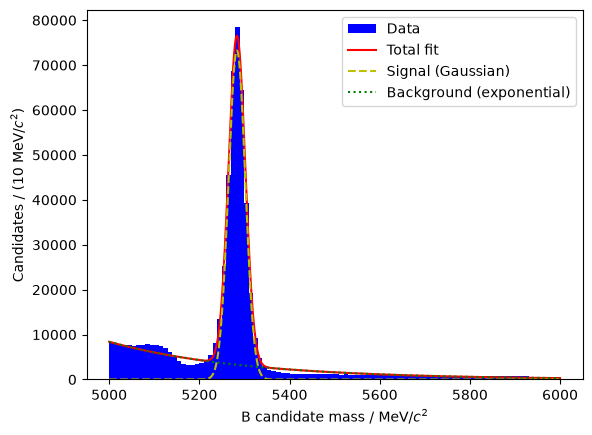

In [ ]:
import zfit

lower, upper = 5000, 6000
b_mass_space = zfit.Space('B invariant mass', (lower, upper))

mean  = zfit.Parameter('mean', 5280, 5000, 6000)
sigma = zfit.Parameter('sigma', 20,    5,  100)
signalYield = zfit.Parameter('signalYield', 1e5, 0, 1e6)

signalPDF = zfit.pdf.Gauss(obs=b_mass_space, mu=mean, sigma=sigma, extended=signalYield)

exponent  = zfit.Parameter('exponent', -0.01, -1e-1, -1e-6)
backgroundYield = zfit.Parameter('backgroundYield', 4e5, 0, 1e6)

backgroundPDF = zfit.pdf.Exponential(obs=b_mass_space, lam=exponent, extended=backgroundYield)

totalPDF = zfit.pdf.SumPDF(pdfs=[signalPDF, backgroundPDF])

zdata = zfit.Data.from_pandas(data, b_mass_space)

nll = zfit.loss.ExtendedUnbinnedNLL(model=totalPDF, data=zdata)

minimizer = zfit.minimize.Minuit()
result = minimizer.minimize(nll)

#Uncertainties from Hesse (the curvature of the likelihood at the minimum)
param_hesse = result.hesse()

mu_fit         = result.params[mean]['value']
sigma_fit      = result.params[sigma]['value']
sig_yield_fit  = result.params[signalYield]['value']
back_yield_fit = result.params[backgroundYield]['value']
exponent_fit   = result.params[exponent]['value']


print(result)
print(f"Function minimum: {result.fmin}")
print(f"Converged: {result.converged}")
print(f"Valid: {result.valid}")


n_bins = 100
bin_width = (upper - lower) / n_bins

plt.hist(b_mass, bins=n_bins, range=(lower, upper),
          color='blue', label='Data')

x = np.linspace(lower, upper, 1000)
plt.plot(x, np.asarray(totalPDF.ext_pdf(x))      * bin_width, 'r-',  label='Total fit')
plt.plot(x, np.asarray(signalPDF.ext_pdf(x))     * bin_width, 'y--', label='Signal (Gaussian)')
plt.plot(x, np.asarray(backgroundPDF.ext_pdf(x)) * bin_width, 'g:',  label='Background (exponential)')

plt.xlabel(r'B candidate mass / MeV/$c^2$')
plt.ylabel(rf'Candidates / ({bin_width:.0f} MeV/$c^2$)')
plt.legend()
plt.show()

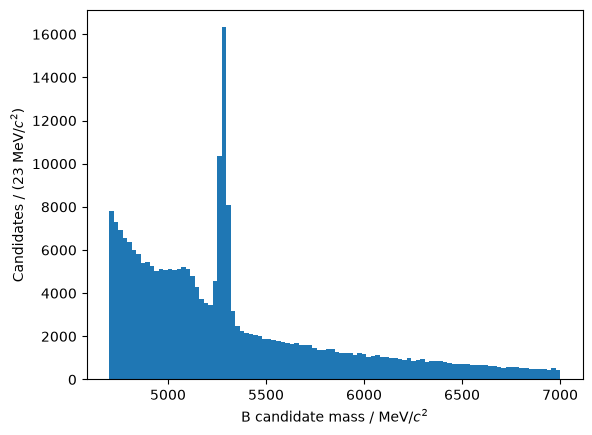

In [29]:
#Most of the real B mesons are actually B -> J/psi K decays. The J/psi is a charm-anticharm meson which decays to our two muons, and
#so, the dimuon system will have a mass consistent with the J/psi meson, 3097 MeV. If we remove these we get

not_jpsi = abs(dimuon_mass - M_JPSI) > 100

plot_mass(b_mass[not_jpsi], r'B candidate mass / MeV/$c^2$')

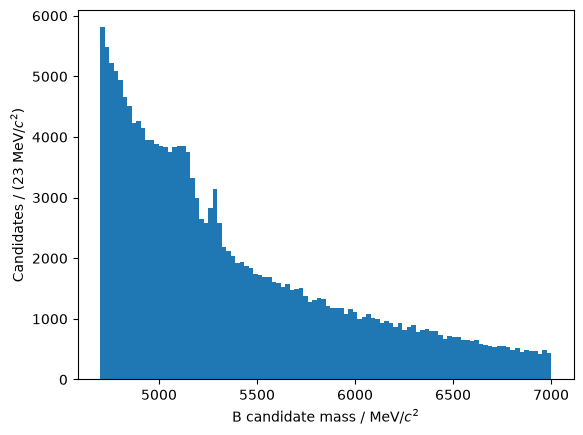

In [30]:
#Now most of what's remaining are actually B -> psi(2S) K decays. The psi(2S) is an excited state of the J/psi.
#It can also decay to our two muons, but now the dimuon system will have a mass consistent with the psi(2S) meson, 3686 MeV.
#If we also remove these, we'll see how much work we've got to do

not_psi2s = abs(dimuon_mass - M_PSI2S) > 100

plot_mass(b_mass[not_jpsi & not_psi2s], r'B candidate mass / MeV/$c^2$')

## Task 2: Dimuon mass spectrum

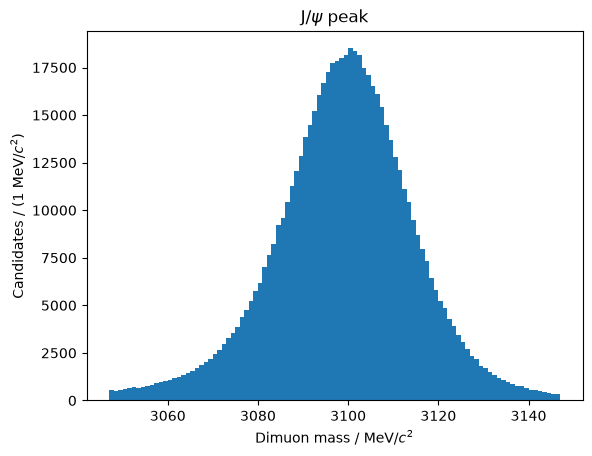

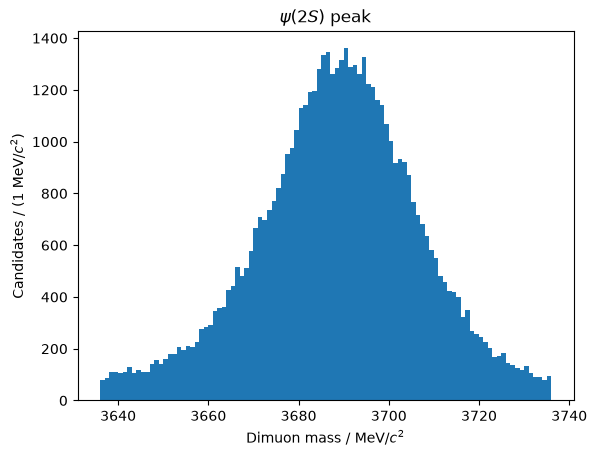

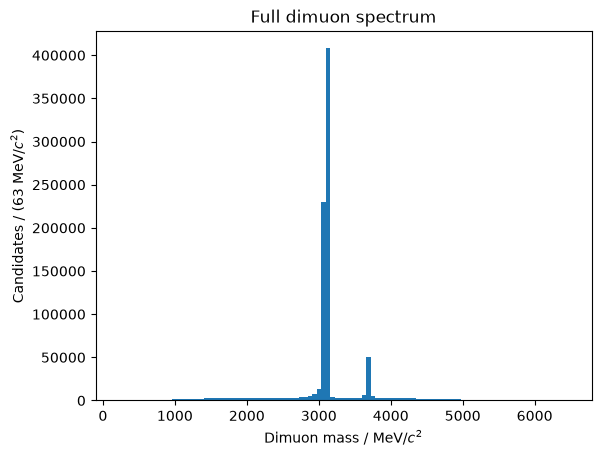

In [31]:
#J/psi and psi(2S) regions of the dimuon spectrum
jpsi_region  = data[abs(dimuon_mass - M_JPSI)  < 50]
psi2s_region = data[abs(dimuon_mass - M_PSI2S) < 50]

plot_mass(jpsi_region['dimuon-system invariant mass'],  r'Dimuon mass / MeV/$c^2$', title=r'J/$\psi$ peak')
plot_mass(psi2s_region['dimuon-system invariant mass'], r'Dimuon mass / MeV/$c^2$', title=r'$\psi(2S)$ peak')
plot_mass(dimuon_mass, r'Dimuon mass / MeV/$c^2$', title='Full dimuon spectrum')

## Task 3: Signal-like and background-like regions
### Signal-like data

In [32]:
#The J/psi region is almost all real B -> J/psi K decays
signal_like = jpsi_region

### Background-like data

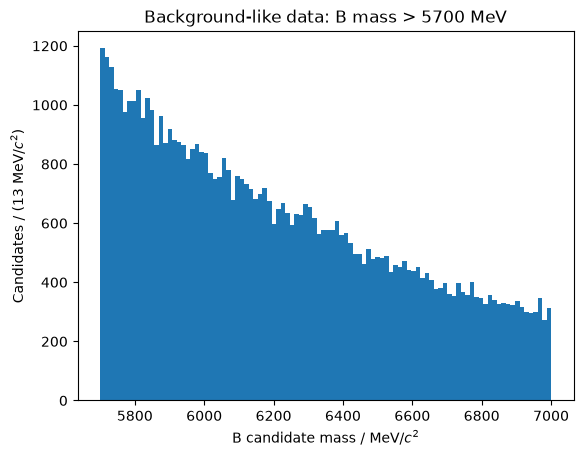

In [33]:
#Nothing real can have a mass this far above the B mass, so this is all random combinations
noise_like = data[b_mass > 5700]

plot_mass(noise_like['B invariant mass'], r'B candidate mass / MeV/$c^2$', title='Background-like data: B mass > 5700 MeV')

### Identify how features vary between datasets

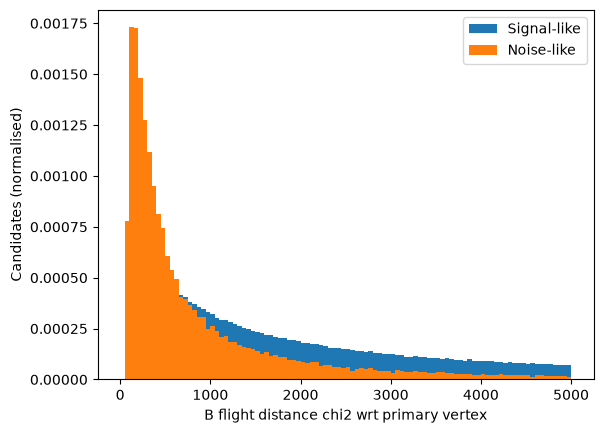

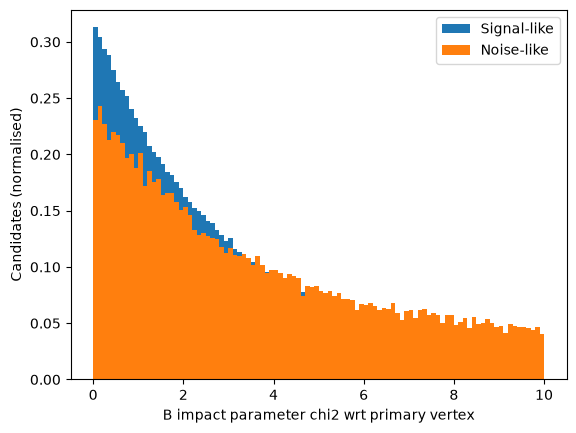

In [34]:
#(variable, plot range)
compare_variables = [
    ('B flight distance chi2 wrt primary vertex',  (0, 5000)),
    ('B impact parameter chi2 wrt primary vertex', (0, 10)),
]

for variable, plot_range in compare_variables:
    plt.hist(signal_like[variable], bins=100, range=plot_range, label='Signal-like', density=True)
    plt.hist(noise_like[variable],  bins=100, range=plot_range, label='Noise-like',  density=True)
    plt.xlabel(variable)
    plt.ylabel('Candidates (normalised)')
    plt.legend()
    plt.show()

In [36]:
#Correlation of every variable with the B mass. Cutting on a variable that is strongly
#correlated with the B mass would change the shape of the mass distribution.

import scipy.stats as stats

r_list = []
for var in data:
    r = np.abs(stats.pearsonr(data[var], b_mass).statistic)
    r_list.append((var, r))

r_list = sorted(r_list, key=lambda x: -np.inf if np.isnan(x[1]) else x[1])
print(tabulate(r_list, headers=['Variable', 'PMCC']))

C:\Users\YaBoiSK\AppData\Local\Temp\ipykernel_3760\411339934.py:8: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r = np.abs(stats.pearsonr(data[var], b_mass).statistic)


Variable                                                                                              PMCC
-------------------------------------------------------------------------------------------  -------------
Isolation: Charged cone angle                                                                nan
dimuon-system cos(angle) between line-of-flight from B-decay vertex and momentum             nan
Same-sign muon PID muon system flag                                                          nan
Opposite-sign muon PID muon system flag                                                      nan
Year                                                                                         nan
dimuon-system 4-momentum y component                                                           4.90215e-05
Same-sign muon 4-momentum x component                                                          0.00015818
B decay vertex y position                                                               

## Task 4: Selection with XGBoost
### Training

In [37]:
import xgboost

model = xgboost.XGBClassifier(eval_metric='auc', early_stopping_rounds=50, n_estimators=1000, learning_rate=0.3, max_depth=6)

nSignalTotal = len(signal_like)
nBackgroundTotal = len(noise_like)

#vary these
chosen_variables = [
'B decay vertex x position',
'B decay vertex y position',
'B decay vertex z position',
'B decay vertex fit chi2',
'B impact parameter wrt primary vertex',
'B impact parameter chi2 wrt primary vertex',
'B flight distance wrt primary vertex',
'B flight distance chi2 wrt primary vertex',
'B cos(angle) between line-of-flight and momentum',
'B magnitude of momentum'
]

#train/test split
nSignalTrain = int(0.9*nSignalTotal)
nSignalTest  = nSignalTotal - nSignalTrain
nBackgroundTrain = int(0.9*nBackgroundTotal)
nBackgroundTest  = nBackgroundTotal - nBackgroundTrain

#train
x_train = pandas.concat([signal_like[chosen_variables][:nSignalTrain], noise_like[chosen_variables][:nBackgroundTrain]], axis=0, ignore_index=True)
y_train = [1]*nSignalTrain + [0]*nBackgroundTrain

#test
x_test = pandas.concat([signal_like[chosen_variables][nSignalTrain:], noise_like[chosen_variables][nBackgroundTrain:]], axis=0, ignore_index=True)
y_test  = [1]*nSignalTest + [0]*nBackgroundTest

model.fit(x_train, y_train, eval_set=[(x_test,y_test)])

[0]	validation_0-auc:0.89977
[1]	validation_0-auc:0.91605
[2]	validation_0-auc:0.92213
[3]	validation_0-auc:0.92627
[4]	validation_0-auc:0.93000
[5]	validation_0-auc:0.93246
[6]	validation_0-auc:0.93445
[7]	validation_0-auc:0.93809
[8]	validation_0-auc:0.93991
[9]	validation_0-auc:0.94150
[10]	validation_0-auc:0.94262
[11]	validation_0-auc:0.94420
[12]	validation_0-auc:0.94489
[13]	validation_0-auc:0.94618
[14]	validation_0-auc:0.94713
[15]	validation_0-auc:0.94790
[16]	validation_0-auc:0.94847
[17]	validation_0-auc:0.94885
[18]	validation_0-auc:0.94984
[19]	validation_0-auc:0.95009
[20]	validation_0-auc:0.95052
[21]	validation_0-auc:0.95100
[22]	validation_0-auc:0.95114
[23]	validation_0-auc:0.95161
[24]	validation_0-auc:0.95182
[25]	validation_0-auc:0.95236
[26]	validation_0-auc:0.95253
[27]	validation_0-auc:0.95273
[28]	validation_0-auc:0.95279
[29]	validation_0-auc:0.95313
[30]	validation_0-auc:0.95336
[31]	validation_0-auc:0.95345
[32]	validation_0-auc:0.95364
[33]	validation_0-au

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",50
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'auc'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


### Results on the test sample

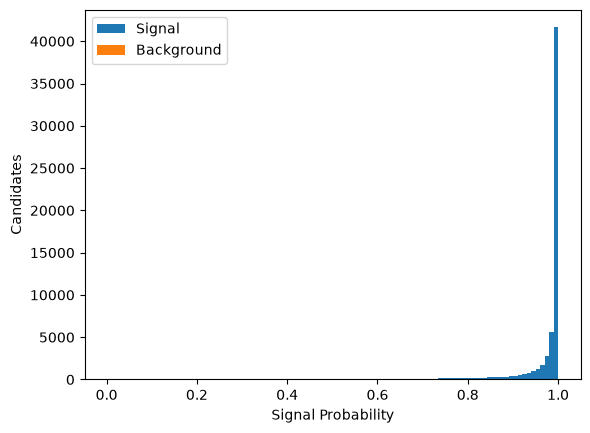

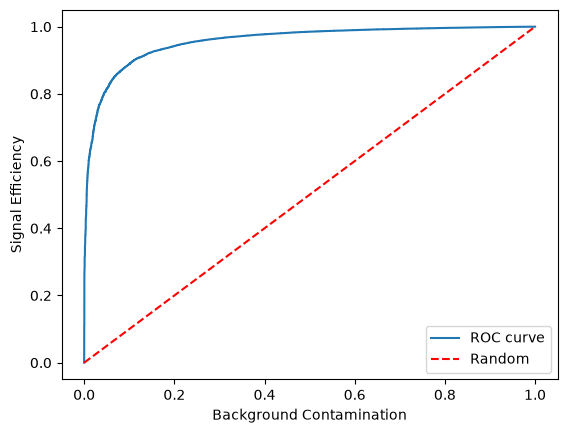

In [38]:
from sklearn.metrics import roc_curve

test_prediction = model.predict_proba(x_test)

plt.hist([p[1] for p,cls in zip(test_prediction, y_test) if cls == 1], bins=100, label='Signal')
plt.hist([p[1] for p,cls in zip(test_prediction, y_test) if cls == 0], bins=100, label='Background')
plt.xlabel(r'Signal Probability')
plt.ylabel(r'Candidates')
plt.legend()
plt.show()

background_accepted, signal_accepted, probabilities_tested = roc_curve(y_test, test_prediction[:,1])
plt.plot(background_accepted, signal_accepted, label='ROC curve')
plt.plot([0,1], [0,1], color='red', linestyle='--', label = 'Random')
plt.xlabel(r'Background Contamination')
plt.ylabel(r'Signal Efficiency')
plt.legend()
plt.show()

### Apply the selection to the full dataset

In [39]:
#Signal probability for every candidate in the dataset
signal_probability = model.predict_proba(data[chosen_variables])[:, 1]

#threshold set at 0.99
passes_bdt = signal_probability > 0.99

## Task 5: K+ mu- two body system

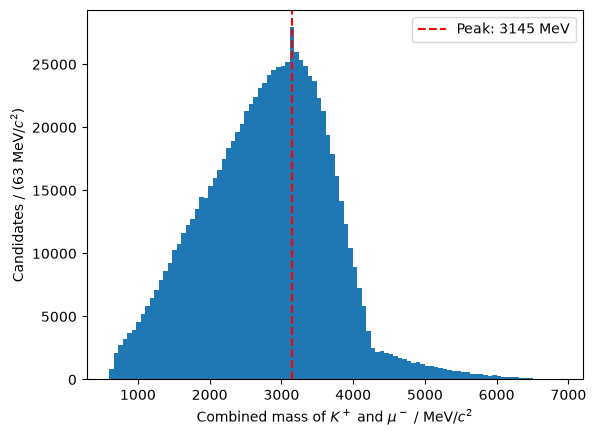

In [40]:
#Using the energies stored in the data (the detector's own mass assignments)
kmu_mass = two_body_mass(data, 'Kaon', 'Opposite-sign muon')

plot_mass(kmu_mass, r'Combined mass of $K^+$ and $\mu^-$ / MeV/$c^2$', show_peak=True)

### Masses correct
Kaon given the kaon mass, muon given the muon mass.

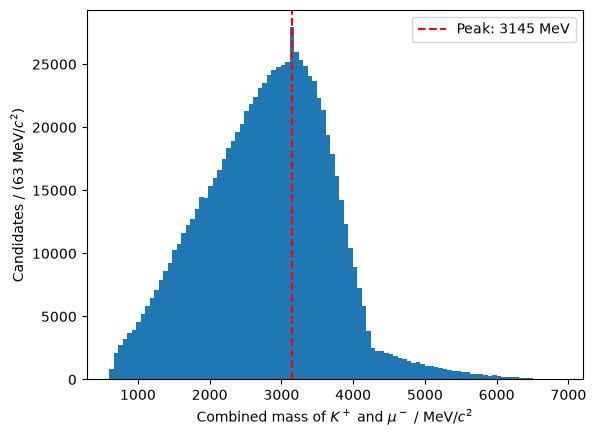

In [41]:
kmu_mass_correct = two_body_mass(data, 'Kaon', 'Opposite-sign muon', M_KAON, M_MUON)

plot_mass(kmu_mass_correct, r'Combined mass of $K^+$ and $\mu^-$ / MeV/$c^2$', show_peak=True)

## Kaon mistaken for a muon (so muon has kaon mass)

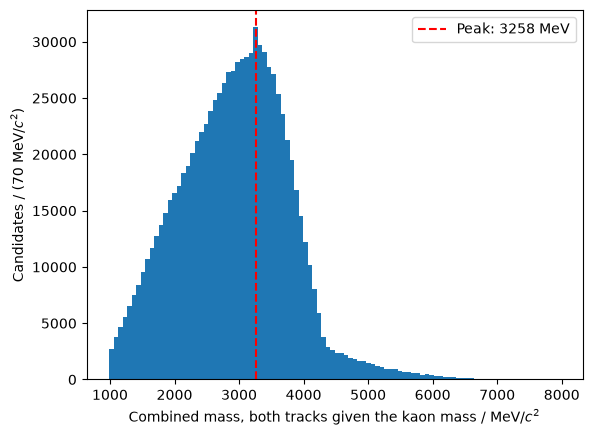

In [42]:
kmu_mass_as_kk = two_body_mass(data, 'Kaon', 'Opposite-sign muon', M_KAON, M_KAON)

plot_mass(kmu_mass_as_kk, r'Combined mass, both tracks given the kaon mass / MeV/$c^2$', show_peak=True)

## Muon mistaken for a kaon (so kaon has muon mass)

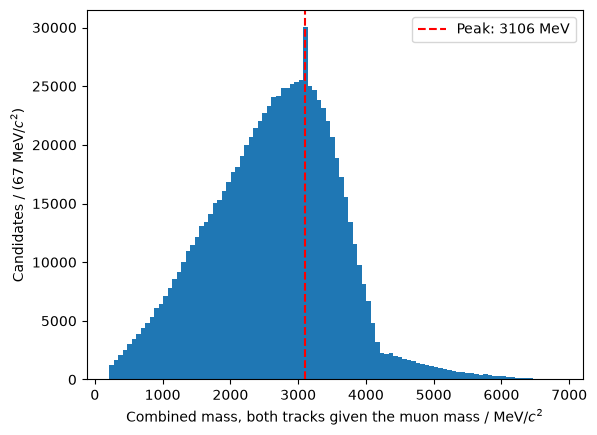

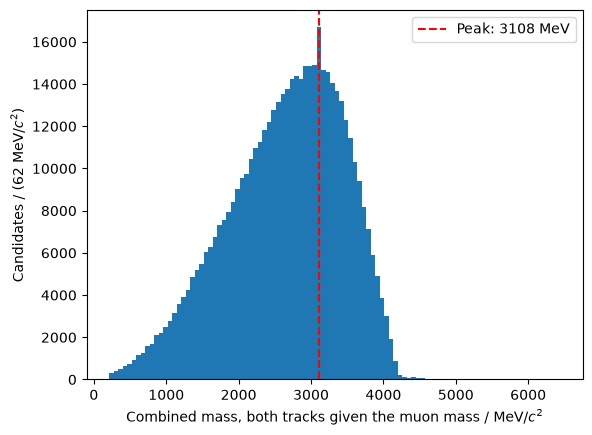

In [43]:
kmu_mass_as_mumu = two_body_mass(data, 'Kaon', 'Opposite-sign muon', M_MUON, M_MUON)

#before the XGBoost selection
plot_mass(kmu_mass_as_mumu, r'Combined mass, both tracks given the muon mass / MeV/$c^2$', show_peak=True)

#after the XGBoost selection
plot_mass(kmu_mass_as_mumu[passes_bdt], r'Combined mass, both tracks given the muon mass / MeV/$c^2$', show_peak=True)

## Kill the peak

after the XGBoost algorithm is used to cut out the background noise the mode is exactly 3097. In general, the peak being close to 3000 MeV/c^2 seems to be a coincidence (from the research that I've done. So a peak within that region or so is normal.). However, the peak at 3097 specifically is not normal. 

We previously cleaned the J/psi decays. However, that assumes muons are identified correctly. If one of the muons registered as a kaon in the detector then the 3097 J/psi decay would register as a 3097 kaon + muon combination. This is the peak we observe here. 

As a temporary solution (to be refined later) we will simply cut out 3097+-50 from this kaon+muon combination. While not perfect, it gets rid off a lot of bad data while not sacrificing too much. A more refined solution involving fits or maybe ML should be implemented at some point

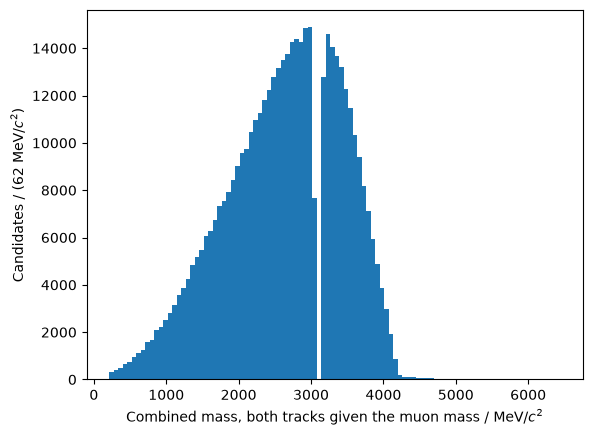

In [44]:
#Veto candidates where the kaon + muon look like a J/psi (the kaon was really a muon)
jpsi_swap_veto = abs(kmu_mass_as_mumu - M_JPSI) > 50

plot_mass(kmu_mass_as_mumu[passes_bdt & jpsi_swap_veto], r'Combined mass, both tracks given the muon mass / MeV/$c^2$')

## Task 6: Finalising the B count

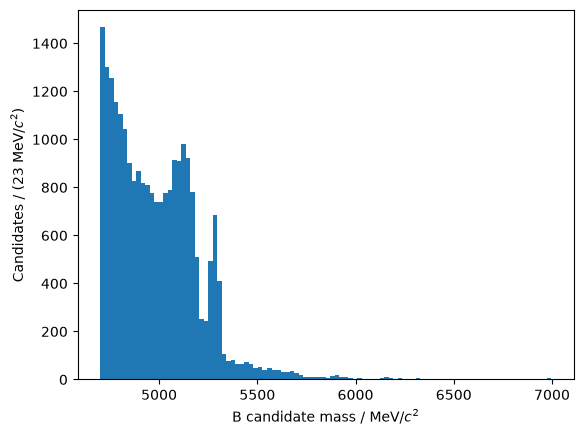

In [45]:
#All cuts for the rare B -> K mu mu decay together
keep = (not_jpsi            #dimuon not a J/psi
    & not_psi2s             #dimuon not a psi(2S)
    & passes_bdt            #XGBoost selection
    & jpsi_swap_veto        #kaon + muon not a J/psi
)

plot_mass(b_mass[keep], r'B candidate mass / MeV/$c^2$')